This follows the path laid out in 'FullFit_ordered1.ipynb' and starts off from the progress and framework made in reflectivity_fitting_v3.ipynb

---
### Imports

Importing and calling ...../Fitting/GenPaths.py
added to path: ['/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/Fitting', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling']
PROPATH variable: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling


------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


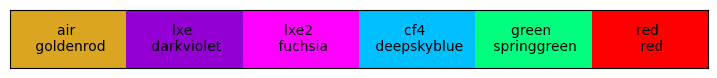

In [1]:
from GenPaths import * # this provides PROPATH which helps load stuff (and the paths to find the PDEhelpers stuff)

import pandas as pd
import matplotlib.pyplot as plt

from scipy import optimize as opt
import iminuit
from iminuit import Minuit

from PDEhelpers.OpticsDataLoader import *
import PDEhelpers.MathEquations as ME
from PDEhelpers.PhotonInfo import * # this calls DataLoader when defining init
# from PDEhelpers.PNJunction import *
import PDEhelpers.PNJunction as PNJ

import PDE_fittingTools as SS

import PDEhelpers.PDEStyle as MS
MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like

rad2deg = 180/np.pi

# MS.ShowMyStyles() # for colors
# ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option


In [2]:
# %run "PDE_fittingFunction.py"

In [3]:
######## High level Fitting Functions ########
def PDE_allArgs(wlen, theta1, FF, tOxide, dp_star, Xpn, dw_star, pe, ph, smoothSigma=None, quantum = False):
    
    photon = PhotonInfo(wlen, theta1)    
    Ttotal = photon.T_total_windowAndOxide(tOxide)
    # Ttotal = photon.Wave_TotalTransmission(tOxide)
    pn = PNJ.PNJunction(tOxide = tOxide, dp_star = dp_star, Xpn = Xpn, dw_star=dw_star, pe = pe, ph = ph)
    Wp, Wn = pn.calcW_both(photon)
    
    if quantum:
        # nyield = (380/wlen)
        cutinWl = 380
        nyield = np.where(wlen < cutinWl, np.sqrt(cutinWl/wlen), 1)
        pe = 1-(1-pe)**nyield
    PDE = FF * Ttotal * (Wp*pe + Wn*ph)
    
    if smoothSigma is not None: # expensive but simple/works/robust
        stepPerSigma = 3
        stepSize = smoothSigma / stepPerSigma
        newXVals = np.arange(min(wlen), max(wlen) + stepSize, stepSize)
        fullerPDEVals = PDE_allArgs(newXVals, theta1, FF, tOxide, dp_star, Xpn, dw_star, pe, ph, smoothSigma = None)
        fullerPDEVals = gaussian_filter1d(fullerPDEVals, sigma=smoothSigma)
        pdeInt = interp1d(newXVals, fullerPDEVals, kind='linear', fill_value=0)
        return pdeInt(wlen)
        
    return PDE

In [4]:
# A different, cool way to do this

# ######## High level Fitting Functions ########
# def is_iterable(x):
#     # print(locals())
#     try:
#         iter(x)
#         return True
#     except TypeError:
#         return False

# def PDE_allArgs(wlen, theta1, FF, tOxide, dp_star, Xpn, dw_star, pe, ph, smoothSigma=None, quantum = False, dh = None):
#     # to use later
#     if smoothSigma is not None:
#         theseArgsDict = locals()
#         del theseArgsDict["wlen"]
#         theseArgsDict["smoothSigma"] = None

#     photon = PhotonInfo(wlen, theta1, dataHelper=dh)    
#     Ttotal = photon.T_total_windowAndOxide(tOxide)
#     # Ttotal = photon.Wave_TotalTransmission(tOxide)
#     pn = PNJ.PNJunction(tOxide = tOxide, dp_star = dp_star, Xpn = Xpn, dw_star=dw_star, pe = pe, ph = ph)
#     Wp, Wn = pn.calcW_both(photon)
    
#     if quantum:
#         # nyield = (380/wlen)
#         cutinWl = 380
#         nyield = np.where(wlen < cutinWl, np.sqrt(cutinWl/wlen), 1)
#         pe = 1-(1-pe)**nyield
#     PDE = FF * Ttotal * (Wp*pe + Wn*ph)
    
#     if smoothSigma is not None: # expensive but simple/works/robust
#         stepSize = smoothSigma / 10
#         newXVals = np.arange(min(wlen), max(wlen) + stepSize, stepSize) # for full array at once. requires interp1d below
#         fullerPDEVals = PDE_allArgs(newXVals, theta1, FF, tOxide, dp_star, Xpn, dw_star, pe, ph, smoothSigma = None)
#         fullerPDEVals = gaussian_filter1d(fullerPDEVals, sigma=smoothSigma) 
#         pdeInt = interp1d(newXVals, fullerPDEVals, kind='linear', fill_value=0)
#         return pdeInt(wlen)

#     # if smoothSigma is not None: # this is a slower way to do it for high granularity
#     #     stepSize = smoothSigma/10
#     #     Nsigma=2        
#     #     xRange = np.arange(-Nsigma*smoothSigma, Nsigma*smoothSigma + stepSize, stepSize)
#     #     gausVals = sps.norm.pdf(x=xRange, loc = 0, scale = smoothSigma)
#     #     gausVals /= np.sum(gausVals) # normalize
#     #     if not is_iterable(wlen):
#     #         wlen = [wlen]
#     #     newPDEloop = [np.sum(gausVals * PDE_allArgs(wlen = xRange + thisX, **theseArgsDict)) for thisX in wlen]
#     #     return np.array(newPDEloop)
        
        
#     return PDE

In [5]:
## plotting PDE if probabilities were 1 (for Wp, Wn)

# xVals = np.arange(300, 1200, 1)
# yPDE_P = PDE_allArgs(xVals, theta1=0, FF=0.6, tOxide=16.5, dp_star=1, Xpn=2e3, dw_star=10e3, pe=1, ph=0, smoothSigma=None, quantum = False)

# yPDE_N = PDE_allArgs(xVals, theta1=0, FF=0.6, tOxide=16.5, dp_star=1, Xpn=2e3, dw_star=10e3, pe=0, ph=1, smoothSigma=None, quantum = False)

# xpnValues = np.linspace()

# plt.plot(xVals, yPDE_P, label='Wp')
# plt.plot(xVals, yPDE_N, label='Wn')
# # plt.plot(xVals, yPDE_P + yPDE_N, label='Wp + Wn')

plt.show()

---
### Loading Data

In [6]:
file_path = os.path.join(PROPATH, "../veraData/HPK_IR_PDE-Feb12_2024-Harry.csv")
df = pd.read_csv(file_path, header=0)

# print(df)
# print(df.info())
print(df.tail())
print("--------------------------")

print(df['Overvoltage'].value_counts())
print(df['Angle'].value_counts())
# print(df['Wavelength'].unique())

data_angles = df['Angle'].unique()
data_voltages = df['Overvoltage'].unique()

# print("Angles:", data_angles)
# print("voltages:", data_voltages)

df = df[(df['Wavelength'] != 399.975) & ((df['Wavelength'] < 695) | (df['Wavelength'] > 705))]

      Wavelength  Angle  Overvoltage  Responsivity       PDE  PDE_error
2188     799.979     60            6  3.429750e-14  0.041089   0.004239
2189     809.978     60            6  3.299900e-14  0.039534   0.003863
2190     820.008     60            6  3.095340e-14  0.037083   0.003730
2191     830.012     60            6  2.754830e-14  0.033003   0.003196
2192     830.012     60            6  2.754830e-14  0.033003   0.003196
--------------------------
Overvoltage
0    260
1    255
2    255
3    255
4    255
5    255
6    254
7    204
8    200
Name: count, dtype: int64
Angle
0     459
15    459
30    459
45    459
60    357
Name: count, dtype: int64


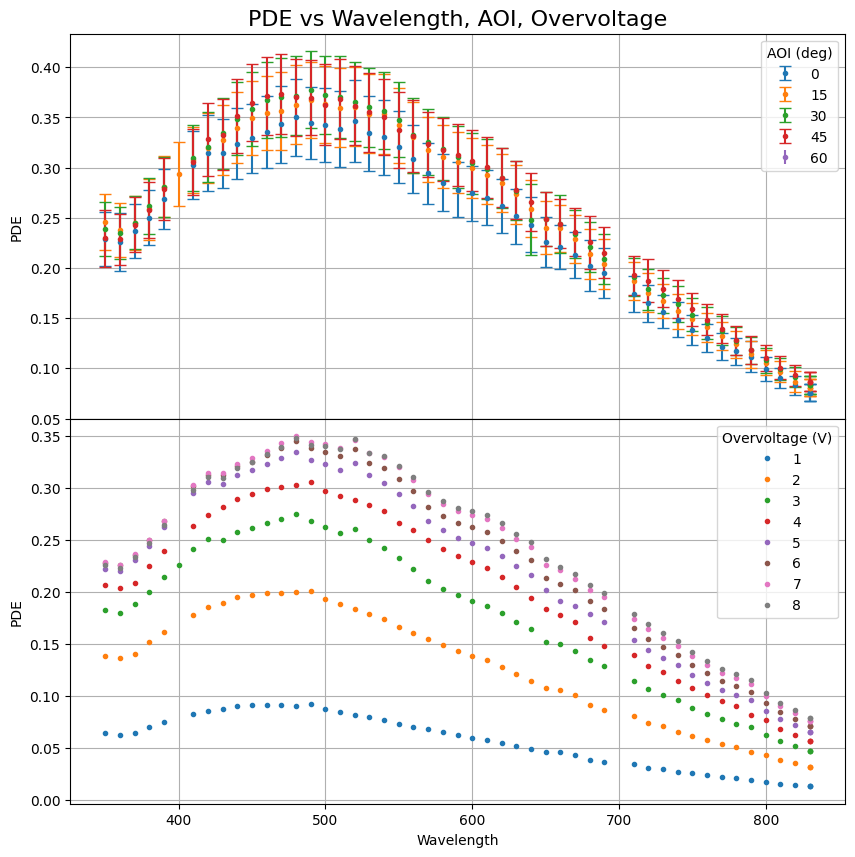

Angles: [0 1 2 3 4 5 6 7 8]
voltages: [0 1 2 3 4 5 6 7 8]


In [7]:
## Plot the data
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize = (10, 10))

# xv4 = df[df['Overvoltage'] == 4]
for angle in data_angles:
    dt1 = df[(df['Angle'] == angle) & (df['Overvoltage'] == 7)]

    dt1.plot(x='Wavelength', y = "PDE", yerr="PDE_error", capsize=4, label = f"{angle:0.0f}", linestyle = "", marker = ".", ax = ax1)
    
ax1.legend(title = "AOI (deg)")
ax1.set_ylabel("PDE")

for voltage in data_voltages[1:]:
    dt2 = df[(df['Angle'] == 0) & (df['Overvoltage'] == voltage)]
    dt2.plot(x='Wavelength', y = "PDE",label = f"{voltage:0.0f}", linestyle = "", marker = ".", ax = ax2)

ax2.legend(title = "Overvoltage (V)")
ax2.set_ylabel("PDE")

ax1.grid(), ax2.grid()
ax1.set_title("PDE vs Wavelength, AOI, Overvoltage", fontsize = 16)
plt.subplots_adjust(hspace=0)
plt.show()
print("Angles:", data_voltages)
print("voltages:", data_voltages)

    Wavelength  Overvoltage  Raw rate     Error  normalized rate
45         380            1   85685.2  4284.260         0.486306
46         380            2  129270.0   102.441         0.733673
47         380            3  151277.0   112.130         0.858569
48         380            4  163067.0   117.333         0.925484
49         380            5  169473.0   120.277         0.961845
50         380            6  172971.0   121.836         0.981696
51         380            7  174974.0   122.416         0.993065
52         380            8  175686.0   122.464         0.997103
53         380            9  176196.0  8809.810         1.000000
{1: 0.486306, 2: 0.733673, 3: 0.858569, 4: 0.925484, 5: 0.961845, 6: 0.981696, 7: 0.993065, 8: 0.997103, 9: 1.0}
---- Harry Pe values ----


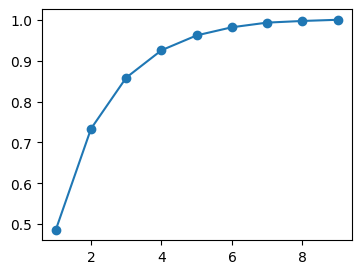

In [8]:
## Loading in Harry's PE data
file_path_pe = os.path.join(PROPATH, "../veraData/HPK_EHPAIR_183K.csv")
df_pe = pd.read_csv(file_path_pe, header=0)

# print(df_pe)
df_pe=df_pe[df_pe['Wavelength'] == 380]
print(df_pe)

harryPe = df_pe['normalized rate'].values
harryPedict = {df_pe["Overvoltage"].values[i]: harryPe[i] for i in range(len(harryPe))}
print(harryPedict)

print("---- Harry Pe values ----")
plt.figure(figsize=(4, 3))
plt.plot(df_pe["Overvoltage"], harryPe, marker = "o")
plt.show()

---
---
### UV high V Dataset
No nested/nuisance pars are required here  


In [9]:
##-- Buiding A1 dataset --##
scaleErrors = 0.3
UVLim = 420
# dataset 0A
v_0A = data_voltages[-1]
v_0A2 = data_voltages[-2]
angle_0A = data_angles[0]

# temporary datasets
dfA_t1 = df[(df['Overvoltage'] == v_0A) & (df['Angle'] == angle_0A) & (df['Wavelength'] < UVLim)]
dfA2_t2 = df[(df['Overvoltage'] == v_0A2) & (df['Angle'] == angle_0A)& (df['Wavelength'] < UVLim)]
data_UV_V = [
    {"wlen":dfA_t1['Wavelength'], "yVals": dfA_t1['PDE'], "yErrs": dfA_t1['PDE_error']*scaleErrors, "theta1": angle_0A}
    ,{"wlen":dfA2_t2['Wavelength'], "yVals": dfA2_t2['PDE'], "yErrs": dfA2_t2['PDE_error']*scaleErrors, "theta1": angle_0A}
    ]

print("voltage wanted:", v_0A, "V")
print("angle wanted:", angle_0A, "deg")
# print("data_UV_V[0]:", data_UV_V[0])

SS.CheckDataSetKey_consistent(data_UV_V, True);

voltage wanted: 8 V
angle wanted: 0 deg
-- CheckDataSetKey_consistent() --
	Dataset(s) have same keys, proceed


---
---
#### parameters shared by everything

In [10]:
FF1 = 0.6
# scaleHarry = 0
fixedPars_Boring = {"FF": FF1, "quantum": False, "smoothSigma": None}

ttGood = 16.5 # good thickness in nm

---
---
### UV high V Fitting: Permutation AE
No nested/nuisance pars are required here  
Global float: 
* float $P_e$, $dp^*$, $t_{oxide}$

In [11]:
# global fixed
print("List of args needed:", SS.GetNames(PDE_allArgs))

fixedPars_AE_UV = {"Xpn": 5e3, "dw_star":10e3, "ph":0.0, **fixedPars_Boring}

floatPars_AE_UV = {"tOxide": ttGood, "dp_star": 1.5, "pe": 0.98}
floatBounds_AE_UV = {"tOxide": (0, 150), "dp_star": (0.0, 14), "pe": (0.2, 1.1)}
# SS.AddNonesToDict(dAddTo=floatBounds_AE_UV, dRef=floatPars_AE_UV)

print("------ Case AE-UV setup ------")
SS.CheckAllConditions_forResiduals(func=PDE_allArgs, dataObj=data_UV_V, dFixed=fixedPars_AE_UV, dFloat=floatPars_AE_UV,
                                   dBounds=floatBounds_AE_UV, yNames=("yVals", "yErrs"), verbose=False)

xoAE_UV, xoAE_UV_Names = SS.BuildX0(floatDict=floatPars_AE_UV, functionToFit=PDE_allArgs)
xABounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_AE_UV, functionToFit=PDE_allArgs)

resTest = SS.GenericResiduals(x0=xoAE_UV, dataObj=data_UV_V, functionToFit=PDE_allArgs, fixedArgs_dict=fixedPars_AE_UV,
                 verbose=True, yNames=("yVals", "yErrs"))
print("residuals test:", resTest)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum']
------ Case AE-UV setup ------
------- GenericResiduals(function=PDE_allArgs) -------
	all input parameters (except data):  ['FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum']
	floating args:  ['tOxide', 'dp_star', 'pe']
	---------------- data block 0 --------------------
		float dict (from x0): {'tOxide': 16.5, 'dp_star': 1.5, 'pe': 0.98}
		fixed dict: {'Xpn': 5000.0, 'dw_star': 10000.0, 'ph': 0.0, 'FF': 0.6, 'quantum': False, 'smoothSigma': None}
		dataDict for function, (keys): {'wlen': [349.999, 359.978, 369.988, '...'], 'theta1': 0}
		dataDict for data (y): {'yVals': [0.2258, 0.223135, 0.233426, '...'], 'yErrs': [0.00868092, 0.009096719999999999, 0.008552579999999999, '...']}
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsDa

------ Case AE-UV Fit ------


  message: Optimization terminated successfully.
  success: True
      fun: 5.082484226826352
        x: [ 2.077e-05  5.612e-01  9.767e-01]
 hess_inv: ┌────┬─────────────────────────┐
           │    │      x0      x1      x2 │
           ├────┼─────────────────────────┤
           │ x0 │  0.0011  0.0000      -0 │
           │ x1 │  0.0000  0.0298 1.29e-3 │
           │ x2 │      -0 1.29e-3  0.0001 │
           └────┴─────────────────────────┘
     nfev: 184
     njev: 0
   minuit: ┌─────────────────────────────────────────────────────────────────────────┐
           │                                Migrad                                   │
           ├──────────────────────────────────┬──────────────────────────────────────┤
           │ FCN = 5.082                      │              Nfcn = 184              │
           │ EDM = 4.53e-05 (Goal: 0.0001)    │            time = 1.1 sec            │
           ├──────────────────────────────────┼──────────────────────────────────────┤
  

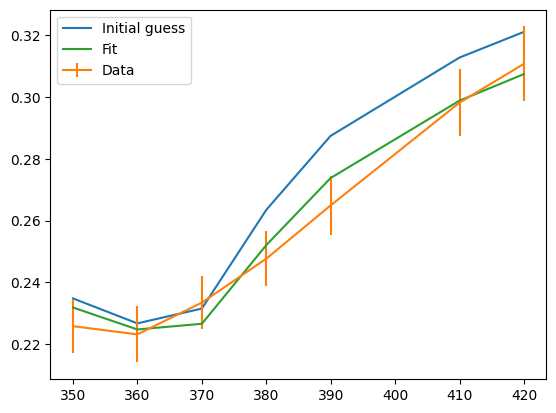

In [12]:
print("------ Case AE-UV Fit ------")
result_AE_UV = iminuit.minimize(SS.GenericResiduals, x0=xoAE_UV, bounds = xABounds, args=(fixedPars_AE_UV, data_UV_V, PDE_allArgs), method='migrad')
SS.GenericResiduals(x0=result_AE_UV.x, dataObj=data_UV_V, functionToFit=PDE_allArgs, fixedArgs_dict=fixedPars_AE_UV, verbose=False, yNames=("yVals", "yErrs"))
print(result_AE_UV)

resDict_AE_UV = SS.GetResDict(result_AE_UV, xoAE_UV_Names)
resDictErrors_AE_UV = SS.GetResErrorDict(result_AE_UV, xoAE_UV_Names)
print("chi2 ish:", result_AE_UV.fun)
print("result:", resDict_AE_UV)
print("errors:", resDictErrors_AE_UV)

# plt.errorbar(x=dataA[0]["wlen"], y=dataA[0]["yVals"], yerr=dataA[0]["yErrs"], label = "Data 8V")
yTest=PDE_allArgs(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **floatPars_AE_UV, **fixedPars_AE_UV)
plt.plot(data_UV_V[0]["wlen"], yTest, label="Initial guess")
plt.errorbar(data_UV_V[0]["wlen"], data_UV_V[0]["yVals"], yerr=data_UV_V[0]["yErrs"], label="Data")

yFit = PDE_allArgs(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **resDict_AE_UV, **fixedPars_AE_UV)
plt.plot(data_UV_V[0]["wlen"], yFit, label="Fit")

plt.legend()
plt.show()

---
### UV high V Fitting: Permutation A
No nested/nuisance pars are required here  
Global float: 
* float $P_e$, $dp^*$
* $t_{oxide} = 16.5$ nm

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum']
------ Case AE-UV setup ------
------ Case AE-UV Fit ------
chi2 score-ish: 6.396328825385719
{'dp_star': 1.1127, 'pe': 0.9318}
errors: {'dp_star': 0.1726, 'pe': 0.0095}


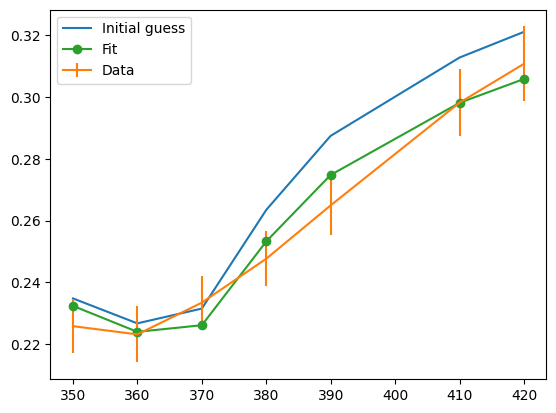

In [13]:
# global fixed
print("List of args needed:", SS.GetNames(PDE_allArgs))

fixedPars_A_UV = {"tOxide": ttGood, "Xpn": 5e3, "dw_star":10e3, "ph":0.0, **fixedPars_Boring}

floatPars_A_UV = { "dp_star": 1.5, "pe": 0.98}
floatBounds_A_UV = {"dp_star": (0.5, 14), "pe": (0.7, 1.1)}
# SS.AddNonesToDict(dAddTo=floatBounds_A_UV, dRef=floatPars_A_UV)

print("------ Case AE-UV setup ------")
SS.CheckAllConditions_forResiduals(func=PDE_allArgs, dataObj=data_UV_V, dFixed=fixedPars_A_UV, dFloat=floatPars_A_UV,
                                   dBounds=floatBounds_A_UV, yNames=("yVals", "yErrs"), verbose=False)
xoAE_UV, xoAE_UV_Names = SS.BuildX0(floatDict=floatPars_A_UV, functionToFit=PDE_allArgs)
xABounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_A_UV, functionToFit=PDE_allArgs)

print("------ Case AE-UV Fit ------")
result_A_UV = iminuit.minimize(SS.GenericResiduals, x0=xoAE_UV, bounds = xABounds, args=(fixedPars_A_UV, data_UV_V, PDE_allArgs), method='migrad')
SS.GenericResiduals(x0=result_A_UV.x, dataObj=data_UV_V, functionToFit=PDE_allArgs, fixedArgs_dict=fixedPars_A_UV, verbose=False, yNames=("yVals", "yErrs"))
# print(result_A_UV)
print("chi2 score-ish:", result_A_UV.fun)


resDict_A_UV = SS.GetResDict(result_A_UV, xoAE_UV_Names)
resDictErrors_A_UV = SS.GetResErrorDict(result_A_UV, xoAE_UV_Names)
print(resDict_A_UV)
print("errors:", resDictErrors_A_UV)

## plotting ##
# plt.errorbar(x=dataA[0]["wlen"], y=dataA[0]["yVals"], yerr=dataA[0]["yErrs"], label = "Data 8V")
yTest=PDE_allArgs(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **floatPars_A_UV, **fixedPars_A_UV)
plt.plot(data_UV_V[0]["wlen"], yTest, label="Initial guess")
plt.errorbar(data_UV_V[0]["wlen"], data_UV_V[0]["yVals"], yerr=data_UV_V[0]["yErrs"], label="Data")

yFit = PDE_allArgs(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **resDict_A_UV, **fixedPars_A_UV)
plt.plot(data_UV_V[0]["wlen"], yFit, label="Fit", marker="o")
plt.legend()
plt.show()

---
### UV high V Fitting: Permutation B
No nested/nuisance pars are required here  
Global float: 
* $dp^*$
* $P_e = 1.0$, $t_{oxide}=16.5$ nm

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum']
------ Case AE-UV setup ------
------ Case B-UV Fit ------
chi2 score-ish: 31.563960971264436
{'dp_star': 2.0182}
errors: {'dp_star': 0.1167}


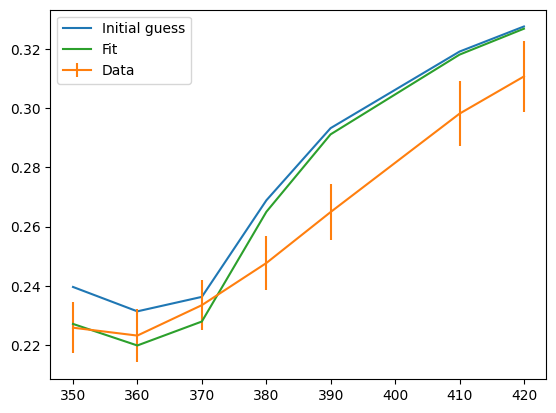

In [14]:
# global fixed
print("List of args needed:", SS.GetNames(PDE_allArgs))

fixedPars_B_UV = {"tOxide": ttGood, "pe": 1.0, "Xpn": 5e3, "dw_star":10e3, "ph":0.0, **fixedPars_Boring}

floatPars_B_UV = { "dp_star": 1.5}
floatBounds_B_UV = {"dp_star": (0.5, 14)}
# SS.AddNonesToDict(dAddTo=floatBounds_B_UV, dRef=floatPars_B_UV)

print("------ Case AE-UV setup ------")
SS.CheckAllConditions_forResiduals(func=PDE_allArgs, dataObj=data_UV_V, dFixed=fixedPars_B_UV, dFloat=floatPars_B_UV,
                                   dBounds=floatBounds_B_UV, yNames=("yVals", "yErrs"), verbose=False)
xoAE_UV, xoAE_UV_Names = SS.BuildX0(floatDict=floatPars_B_UV, functionToFit=PDE_allArgs)
xABounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_B_UV, functionToFit=PDE_allArgs)

print("------ Case B-UV Fit ------")
result_B_UV = iminuit.minimize(SS.GenericResiduals, x0=xoAE_UV, bounds = xABounds, args=(fixedPars_B_UV, data_UV_V, PDE_allArgs), method='migrad')
SS.GenericResiduals(x0=result_B_UV.x, dataObj=data_UV_V, functionToFit=PDE_allArgs, fixedArgs_dict=fixedPars_B_UV, verbose=False, yNames=("yVals", "yErrs"))
# print(result_B_UV)
print("chi2 score-ish:", result_B_UV.fun)

resDict_B_UV = SS.GetResDict(result_B_UV, xoAE_UV_Names)
resDictErrors_B_UV = SS.GetResErrorDict(result_B_UV, xoAE_UV_Names)
print(resDict_B_UV)
print("errors:", resDictErrors_B_UV)

## plotting ##
# plt.errorbar(x=dataA[0]["wlen"], y=dataA[0]["yVals"], yerr=dataA[0]["yErrs"], label = "Data 8V")
yTest=PDE_allArgs(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **floatPars_B_UV, **fixedPars_B_UV)
plt.plot(data_UV_V[0]["wlen"], yTest, label="Initial guess")
plt.errorbar(data_UV_V[0]["wlen"], data_UV_V[0]["yVals"], yerr=data_UV_V[0]["yErrs"], label="Data")

yFit = PDE_allArgs(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **resDict_B_UV, **fixedPars_B_UV)
plt.plot(data_UV_V[0]["wlen"], yFit, label="Fit")

plt.legend()
plt.show()

---
### UV high V Fitting: Permutation BE
No nested/nuisance pars are required here  
* float: $dp^*$, $t_{oxide}$
* $P_e = 1.0$

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum']
------ Case AE-UV setup ------
------ Case AE-UV Fit ------
chi2 score-ish: 7.852288058811995
{'tOxide': 1.0002, 'dp_star': 0.8839}
errors: {'tOxide': 0.0602, 'dp_star': 0.1152}


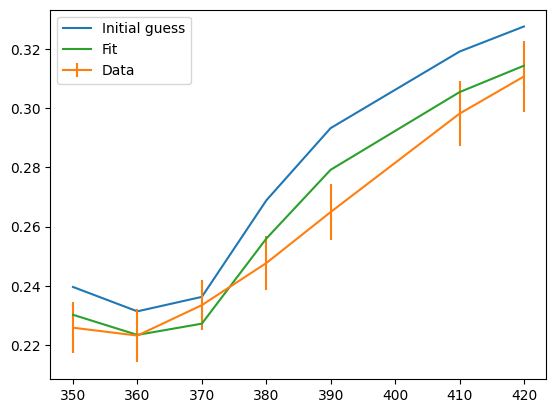

In [15]:
# global fixed
print("List of args needed:", SS.GetNames(PDE_allArgs))

fixedPars_BE_UV = {"pe": 1.0, "Xpn": 5e3, "dw_star":10e3, "ph":0.0, **fixedPars_Boring}

floatPars_BE_UV = {"tOxide": ttGood, "dp_star": 1.5}
floatBounds_BE_UV = {"tOxide": (1, 10), "dp_star": (0.5, 15)}

print("------ Case AE-UV setup ------")
SS.CheckAllConditions_forResiduals(func=PDE_allArgs, dataObj=data_UV_V, dFixed=fixedPars_BE_UV, dFloat=floatPars_BE_UV,
                                   dBounds=floatBounds_BE_UV, yNames=("yVals", "yErrs"), verbose=False)
xoAE_UV, xoAE_UV_Names = SS.BuildX0(floatDict=floatPars_BE_UV, functionToFit=PDE_allArgs)
xABounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_BE_UV, functionToFit=PDE_allArgs)

print("------ Case AE-UV Fit ------")
result_BE_UV = iminuit.minimize(SS.GenericResiduals, x0=xoAE_UV, bounds = xABounds, args=(fixedPars_BE_UV, data_UV_V, PDE_allArgs), method='migrad')
SS.GenericResiduals(x0=result_BE_UV.x, dataObj=data_UV_V, functionToFit=PDE_allArgs, fixedArgs_dict=fixedPars_BE_UV, verbose=False, yNames=("yVals", "yErrs"))
# print(result_BE_UV)
print("chi2 score-ish:", result_BE_UV.fun)

resDict_BE_UV = SS.GetResDict(result_BE_UV, xoAE_UV_Names)
resDictErrors_BE_UV = SS.GetResErrorDict(result_BE_UV, xoAE_UV_Names)
print(resDict_BE_UV)
print("errors:", resDictErrors_BE_UV)

## plotting ##
# plt.errorbar(x=dataA[0]["wlen"], y=dataA[0]["yVals"], yerr=dataA[0]["yErrs"], label = "Data 8V")
yTest=PDE_allArgs(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **floatPars_BE_UV, **fixedPars_BE_UV)
plt.plot(data_UV_V[0]["wlen"], yTest, label="Initial guess")
plt.errorbar(data_UV_V[0]["wlen"], data_UV_V[0]["yVals"], yerr=data_UV_V[0]["yErrs"], label="Data")

yFit = PDE_allArgs(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **resDict_BE_UV, **fixedPars_BE_UV)
plt.plot(data_UV_V[0]["wlen"], yFit, label="Fit")

plt.legend()
plt.show()

---
---
### UV all V Dataset
Now $P_e$ is a nuisance parameter (float or fixed)
* __A__: float nested: $P_e$
* __C__: fix $P_e$ to Harry's values
* __E__: float global: $t_{oxide}$ ??

Will attempt A, C, EC


In [16]:
##-- Buiding A1 dataset --##
scaleErrors = 1.0
# dataset 0A
v_0A = data_voltages[-1]
v_0A2 = data_voltages[-2]
angle_0A = data_angles[0]
print(data_voltages[1:])

data_UV_all = []
voltageTracker = []
for V in data_voltages[1:]:
    voltageTracker.append(V)
    dfA_t1 = df[(df['Overvoltage'] == V) & (df['Angle'] == angle_0A) & (df['Wavelength'] < UVLim)]
    oneD_dict = {"wlen":dfA_t1['Wavelength'], "yVals": dfA_t1['PDE'], "yErrs": dfA_t1['PDE_error']*scaleErrors, "theta1": angle_0A}
    data_UV_all.append(oneD_dict)

SS.CheckDataSetKey_consistent(data_UV_all, True);
print(voltageTracker)

[1 2 3 4 5 6 7 8]
-- CheckDataSetKey_consistent() --
	Dataset(s) have same keys, proceed
[1, 2, 3, 4, 5, 6, 7, 8]


In [17]:
## Building different Nuisance Parameter datasets
data_UVall_A = [] # float Pe
data_UVall_C = [] # use Harry's fixed Pe

for V, oneD in zip(voltageTracker, data_UV_all):
    
    nuisFixed_C = {"pe": harryPedict[V]}
    print("V:", V, "pe:", harryPedict[V])
    
    nuisFloat_A = {"pe": harryPedict[V]}
    nuiseFloatBounds_A = {"pe": (0.0, 1.1)}
    
    odFullA = SS.OneNuisanceDataSet(oneDData=oneD, nuisanceFloat=nuisFloat_A, nuisanceBounds=nuiseFloatBounds_A, nuisanceFixed={})
    odFullA.extraV = V
    odFullC = SS.OneNuisanceDataSet(oneDData=oneD, nuisanceFloat={}, nuisanceBounds={}, nuisanceFixed=nuisFixed_C)
    odFullC.extraV = V
    
    data_UVall_A.append(odFullA)
    data_UVall_C.append(odFullC)

V: 1 pe: 0.486306
V: 2 pe: 0.733673
V: 3 pe: 0.858569
V: 4 pe: 0.925484
V: 5 pe: 0.961845
V: 6 pe: 0.981696
V: 7 pe: 0.993065
V: 8 pe: 0.997103


---
### UV All V Fitting: Permutation A (nested Pe float)

* global float: $dp^*$
* local float: $P_e$

In [18]:
# global fixed
print("List of args needed:", SS.GetNames(PDE_allArgs))

fixedPars_global_A = {"tOxide":ttGood, "Xpn": 5e3, "dw_star":10e3, "ph":0.0, **fixedPars_Boring}

floatPars_global_A = {"dp_star": 5}
floatBounds_A_UV = {"dp_star": (0.5, 15)}

x0_global_A, x0_global_A_Names = SS.BuildX0(floatDict=floatPars_global_A, functionToFit=PDE_allArgs)
x0_global_A_bounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_A_UV, functionToFit=PDE_allArgs)

print("------ Case A-UVall setup ------")

SS.GenericResiduals_Nuisance_1(globalFloat=x0_global_A, globalFixed=fixedPars_global_A, dataPackage=data_UVall_A,
                               functionToFit=PDE_allArgs, verbose=False)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum']
------ Case A-UVall setup ------


118.31728105165408

In [19]:
globalFit_UVall_A = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global_A, bounds = x0_global_A_bounds,
                                     args=(fixedPars_global_A, data_UVall_A, PDE_allArgs), method='migrad')
SS.GenericResiduals_Nuisance_1(globalFloat=globalFit_UVall_A.x, globalFixed=fixedPars_global_A, dataPackage=data_UVall_A,
                               functionToFit=PDE_allArgs, verbose=False)
print("done fit")

done fit


In [20]:
# print(globalFit_UVall_A)
resDict_A_UVall = SS.GetResDict(globalFit_UVall_A, x0_global_A_Names)
resErrors_A_UVall = SS.GetResErrorDict(globalFit_UVall_A, x0_global_A_Names)


print("------ Case A-UVall Fit ------")

print("chi2 score-ish:", globalFit_UVall_A.fun)
print(resDict_A_UVall)
print(resErrors_A_UVall)

peVals_A = [dc.resultDict["pe"] for dc in data_UVall_A]
peVals_A_dict = {dc.extraV: dc.resultDict["pe"] for dc in data_UVall_A}
peErrs_A_dict = {dc.extraV: dc.resultErrorsDict["pe"] for dc in data_UVall_A}
print("peVals_A_dict:", peVals_A_dict)
print("peErrs_A_dict:", peErrs_A_dict)

------ Case A-UVall Fit ------
chi2 score-ish: 2.2628755267139553
{'dp_star': 1.0387}
{'dp_star': 0.2456}
peVals_A_dict: {1: 0.2586, 2: 0.5591, 3: 0.7433, 4: 0.8307, 5: 0.911, 6: 0.9321, 7: 0.9347, 8: 0.9219}
peErrs_A_dict: {1: 0.0068, 2: 0.0193, 3: 0.0182, 4: 0.0199, 5: 0.0221, 6: 0.0253, 7: 0.0288, 8: 0.0308}


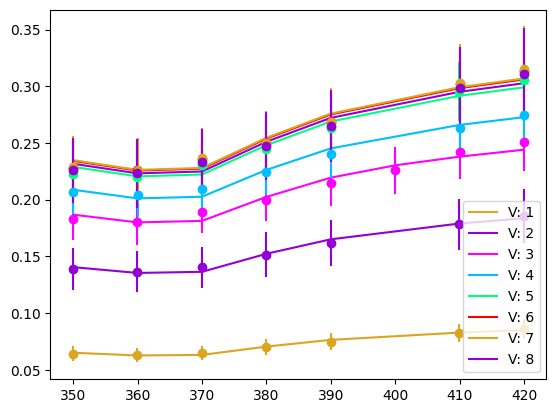

In [21]:
dictA_toPlot = {**resDict_A_UVall, **fixedPars_global_A}
for dc in data_UVall_A:
    oneD = dc.oneDData[0]
    xwlen = oneD["wlen"]
    y = oneD["yVals"]
    yErrs = oneD["yErrs"]
    
    # localPE = dc.resultDict["pe"]
    # print(dc.resultDict)
    col = ms.GetNextColor()
    
    yFit = PDE_allArgs(wlen=xwlen, theta1=oneD["theta1"], **dc.resultDict,  **dictA_toPlot)
    plt.plot(xwlen, yFit, color = col, label=f"V: {dc.extraV}")
    
    plt.errorbar(xwlen, y, yerr=yErrs, color = col, linestyle = "", marker="o")
    
plt.legend()
plt.show()


pe offset: [-0.227706 -0.174573 -0.115269 -0.094784 -0.050845 -0.049596 -0.058365
 -0.075203]
pe ratio: [-0.88053364 -0.31223931 -0.15507736 -0.11410136 -0.05581229 -0.05320888
 -0.06244249 -0.08157392]


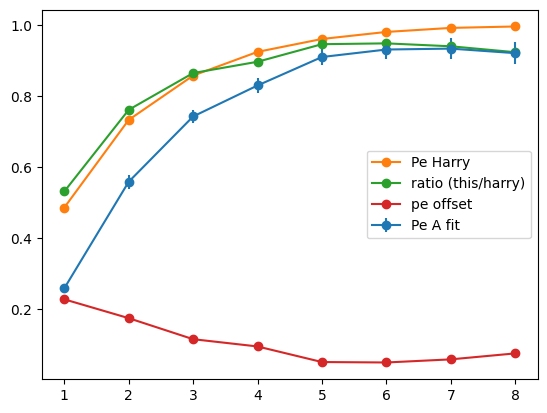

In [22]:
peHarry = np.array([harryPedict[V] for V in voltageTracker])
ype = [peVals_A_dict[V] for V in voltageTracker]
ypeErrs = [peErrs_A_dict[V] for V in voltageTracker]

plt.errorbar(voltageTracker, ype, yerr=ypeErrs, marker="o", label="Pe A fit")
plt.plot(voltageTracker, peHarry, marker="o", label="Pe Harry")

print("pe offset:", peVals_A - peHarry)
print("pe ratio:", 1-peHarry/peVals_A)

plt.plot(voltageTracker, peVals_A/peHarry, marker="o", label="ratio (this/harry)")
plt.plot(voltageTracker, peHarry-peVals_A, marker="o", label="pe offset")

plt.legend()

---
### UV All V Nested Fitting: Permutation C

* global: $dp^*$
* fixed: $T_{oxide}$
* fixed local: $P_e$ - Harry's

In [23]:
print("List of args needed:", SS.GetNames(PDE_allArgs))

fixedPars_global_C = {"tOxide":ttGood, "Xpn": 0.6e3, "dw_star": 5e3, "ph":0.0, **fixedPars_Boring}

floatPars_global_C_UVall = {"dp_star": 5}
floatBounds_C_UVall = {"dp_star": (0.5, 15)}

x0_global_C, x0_global_C_Names = SS.BuildX0(floatDict=floatPars_global_C_UVall, functionToFit=PDE_allArgs)
x0_global_C_bounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_C_UVall, functionToFit=PDE_allArgs)

print("------ Case A-UVall setup ------")

SS.GenericResiduals_Nuisance_1(globalFloat=x0_global_C, globalFixed=fixedPars_global_C, dataPackage=data_UVall_C,
                                 functionToFit=PDE_allArgs, verbose=False)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum']
------ Case A-UVall setup ------


391.3237988814164

In [24]:
globalFit_UVall_C = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global_C, bounds = x0_global_C_bounds,
                                        args=(fixedPars_global_C, data_UVall_C, PDE_allArgs), method='migrad')
SS.GenericResiduals_Nuisance_1(globalFloat=globalFit_UVall_C.x, globalFixed=fixedPars_global_C, dataPackage=data_UVall_C,
                                    functionToFit=PDE_allArgs, verbose=False)
resDict_C_UVall = SS.GetResDict(globalFit_UVall_C, x0_global_C_Names)
print(resDict_C_UVall)

print("------ Case C-UVall Fit ------")
print("chi2 ish:", globalFit_UVall_C.fun)

{'dp_star': 4.295}
------ Case C-UVall Fit ------
chi2 ish: 384.30778778920626


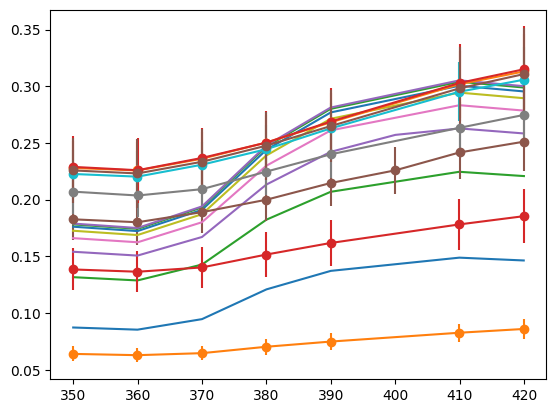

In [25]:
dp_fitC = globalFit_UVall_C.x[0]

dictC_toPlot = {"dp_star":dp_fitC, **fixedPars_global_C}
for dc in data_UVall_C:
    oneD = dc.oneDData[0]
    xwlen = oneD["wlen"]
    y = oneD["yVals"]
    yErrs = oneD["yErrs"]
    
    yFit = PDE_allArgs(wlen=xwlen, theta1=oneD["theta1"], **dc.mDict_nuisFixed,  **dictC_toPlot)
    plt.plot(xwlen, yFit, label=f"Fit V: {dc.extraV}")
    
    plt.errorbar(xwlen, y, yerr=yErrs, label=f"Data V: {dc.extraV}", marker="o")

---
### UV All V Nested Fitting: Permutation CE

* global: $dp^*$, $t_{oxide}$
* fixed local: $P_e$ - Harry's

In [26]:
print("List of args needed:", SS.GetNames(PDE_allArgs))

fixedPars_global_CE = {"Xpn": 5e3, "dw_star":10e3, "ph":0.0, **fixedPars_Boring}

floatPars_global_CE_UVall = {"dp_star": 50, "tOxide": ttGood}
floatBounds_CE_UVall = {"dp_star": (0.5, 100), "tOxide": (0, 120)}

x0_global_CE, x0_global_CE_Names = SS.BuildX0(floatDict=floatPars_global_CE_UVall, functionToFit=PDE_allArgs)
x0_global_CE_bounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_CE_UVall, functionToFit=PDE_allArgs)

print("------ Case CE -UVall setup ------")

SS.GenericResiduals_Nuisance_1(globalFloat=x0_global_CE, globalFixed=fixedPars_global_CE, dataPackage=data_UVall_C,
                                    functionToFit=PDE_allArgs, verbose=False)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum']
------ Case CE -UVall setup ------


2620.742585993098

In [27]:
globalFit_UVall_CE = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global_CE, bounds = x0_global_CE_bounds,
                                        args=(fixedPars_global_CE, data_UVall_C, PDE_allArgs), method='migrad')
SS.GenericResiduals_Nuisance_1(globalFloat=globalFit_UVall_CE.x, globalFixed=fixedPars_global_CE, dataPackage=data_UVall_C,
                                    functionToFit=PDE_allArgs, verbose=False)

print("------ Case CE-UVall Fit ------")
# print(globalFit_UVall_CE)
global_CE_dict = SS.GetResDict(globalFit_UVall_CE, x0_global_CE_Names)
global_CE_dict_errors = SS.GetResErrorDict(globalFit_UVall_CE, x0_global_CE_Names)
print(global_CE_dict)
print(global_CE_dict_errors)

------ Case CE-UVall Fit ------
{'tOxide': 0.0002, 'dp_star': 3.1006}
{'tOxide': 0.0978, 'dp_star': 0.1795}


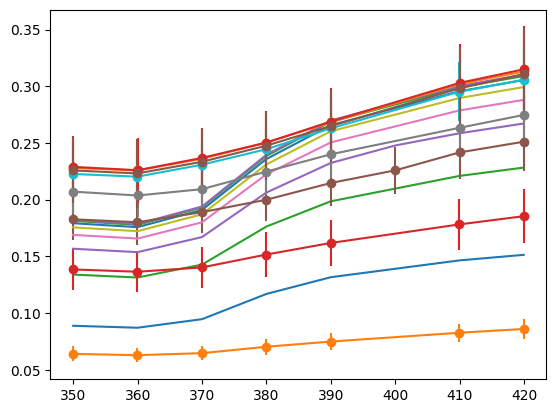

In [28]:
dp_fitCE = global_CE_dict["dp_star"]
tt_fitCE = global_CE_dict["tOxide"]

dictCE_toPlot = {"dp_star":dp_fitCE, "tOxide":tt_fitCE, **fixedPars_global_CE}

for dc in data_UVall_C:
    oneD = dc.oneDData[0]
    xwlen = oneD["wlen"]
    y = oneD["yVals"]
    yErrs = oneD["yErrs"]
    
    yFit = PDE_allArgs(wlen=xwlen, theta1=oneD["theta1"], **dc.mDict_nuisFixed,  **dictCE_toPlot)
    plt.plot(xwlen, yFit, label=f"Fit V: {dc.extraV}")
    
    plt.errorbar(xwlen, y, yerr=yErrs, label=f"Data V: {dc.extraV}", marker="o")

---
---
### Fitting Entire Range - Vis
Fix the P parameters (Pe, dpStar)

---
### Standard Vis fit - Permutation __S__

Front of junction is fixed
* fixed (nested/global): $P_e$, $d_p^*$ = values from fit A
* float nested: $P_h$
* float global: $X_{PN}$, $dw^*$

In [29]:
##-- Buiding Vis all dataset --##
v_0A = data_voltages[-1]
angle_0A = data_angles[0]
print(data_voltages[1:])

data_Vis_allS = []
onlyData_vis_all = []
for V in voltageTracker:
    dfA_t1 = df[(df['Overvoltage'] == V) & (df['Angle'] == angle_0A)]
    oneD_dict = {"wlen":dfA_t1['Wavelength'], "yVals": dfA_t1['PDE'], "yErrs": dfA_t1['PDE_error']*scaleErrors, "theta1": angle_0A}
    
    fixedNuisDict = {"pe":peVals_A_dict[V]}
    floatNuisDict = {"ph": 0.15}
    floatBoundsNuisDict = {"ph": (0.0, 1.1)}
    odFullA = SS.OneNuisanceDataSet(oneDData=oneD_dict, nuisanceFloat=floatNuisDict, nuisanceBounds=floatBoundsNuisDict,
                                    nuisanceFixed=fixedNuisDict)
    odFullA.extraV = V
    data_Vis_allS.append(odFullA)
    onlyData_vis_all.append(oneD_dict)

SS.CheckDataSetKey_consistent(onlyData_vis_all, True);
type(data_Vis_allS[0].oneDData);

[1 2 3 4 5 6 7 8]
-- CheckDataSetKey_consistent() --
	Dataset(s) have same keys, proceed


In [30]:
print("List of args needed:", SS.GetNames(PDE_allArgs))
print("using results from UV_A", resDict_A_UVall)

fixedPars_Vis_S = {"tOxide":ttGood, **resDict_A_UVall, **fixedPars_Boring}
print("\nfixed inputs:", fixedPars_Vis_S)

floatPars_Vis_S = {"Xpn": 0.6e3, "dw_star": 5e3}
floatParBounds_Vis_S = {"Xpn": (0.2e3, 8e3), "dw_star": (3e3, 20e3)}

x0_global_S, x0_global_S_Names = SS.BuildX0(floatDict=floatPars_Vis_S, functionToFit=PDE_allArgs)
x0_global_S_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_Vis_S, functionToFit=PDE_allArgs)

print("------ Case S - Vis all ------")
SS.GenericResiduals_Nuisance_1(globalFloat=x0_global_S, globalFixed=fixedPars_Vis_S, dataPackage=data_Vis_allS,
                               functionToFit=PDE_allArgs, verbose=False)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum']
using results from UV_A {'dp_star': 1.0387}

fixed inputs: {'tOxide': 16.5, 'dp_star': 1.0387, 'FF': 0.6, 'quantum': False, 'smoothSigma': None}
------ Case S - Vis all ------


277.89498005489435

In [31]:
globalFit_Visall_S = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global_S, bounds = x0_global_S_bounds,
                                        args=(fixedPars_Vis_S, data_Vis_allS, PDE_allArgs), method='migrad')
SS.GenericResiduals_Nuisance_1(globalFloat=globalFit_Visall_S.x, globalFixed=fixedPars_Vis_S, dataPackage=data_Vis_allS,
                                    functionToFit=PDE_allArgs, verbose=False)
print("Done fit!")


Done fit!


In [32]:
# print(globalFit_Visall_S)
print("score:", globalFit_Visall_S.fun)
resDict_VisAll_S = SS.GetResDict(globalFit_Visall_S, x0_global_S_Names)
resDictError_Visall_S = SS.GetResErrorDict(globalFit_Visall_S, x0_global_S_Names)
print("from UV fit:", resDict_A_UVall)
print("error UV fit:", resErrors_A_UVall)
print(resDict_VisAll_S)
print(resDictError_Visall_S)

phFull_dict_S = {dc.extraV: (dc.resultDict["ph"], dc.resultErrorsDict["ph"]) for dc in data_Vis_allS}
peFull_dict_A = {dc.extraV: (dc.resultDict["pe"], dc.resultErrorsDict["pe"]) for dc in data_UVall_A}

print("pe:", peFull_dict_A)
print("ph:", phFull_dict_S)


score: 61.50738393067837
from UV fit: {'dp_star': 1.0387}
error UV fit: {'dp_star': 0.2456}
{'Xpn': 1838.8383, 'dw_star': 8914.5004}
{'Xpn': 58.3462, 'dw_star': 898.9738}
pe: {1: (0.2586, 0.0068), 2: (0.5591, 0.0193), 3: (0.7433, 0.0182), 4: (0.8307, 0.0199), 5: (0.911, 0.0221), 6: (0.9321, 0.0253), 7: (0.9347, 0.0288), 8: (0.9219, 0.0308)}
ph: {1: (0.0134, 0.0021), 2: (0.0643, 0.0066), 3: (0.1268, 0.007), 4: (0.1865, 0.0081), 5: (0.2199, 0.0088), 6: (0.264, 0.0106), 7: (0.3107, 0.0129), 8: (0.3436, 0.015)}


{'dp_star': 1.0387, 'Xpn': 1838.8383, 'dw_star': 8914.5004, 'tOxide': 16.5, 'FF': 0.6, 'quantum': False, 'smoothSigma': None}


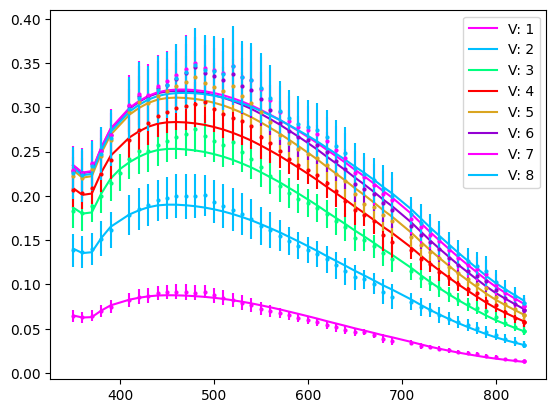

hi


In [33]:
dict_visAll_S_final = {**resDict_A_UVall, **resDict_VisAll_S, **fixedPars_Vis_S}
print(dict_visAll_S_final)

for dc in data_Vis_allS:
    oneD = dc.oneDData[0]
    xwlen = oneD["wlen"]
    y = oneD["yVals"]
    yErrs = oneD["yErrs"]
    
    voltage = dc.extraV
    localPe = peFull_dict_A[voltage][0]
    localPh = phFull_dict_S[voltage][0]
    pArgs = {"pe": localPe, **dc.resultDict}
    
    col = ms.GetNextColor()
    
    yFit = PDE_allArgs(wlen=xwlen, theta1=oneD["theta1"], **dict_visAll_S_final, **pArgs)
    plt.plot(xwlen, yFit, color = col, label=f"V: {dc.extraV}")
    
    plt.errorbar(xwlen, y, yerr=yErrs, color = col, linestyle = "", marker="o", markersize=2)
    
plt.legend()
plt.show()
print("hi")

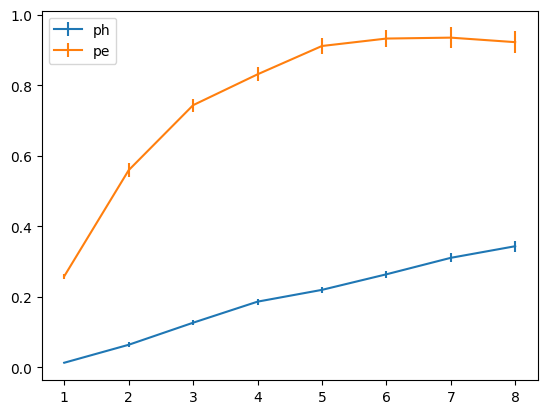

In [34]:
yph = [phFull_dict_S[voltage][0] for voltage in voltageTracker]
yphErr = [phFull_dict_S[voltage][1] for voltage in voltageTracker]
ype = [peFull_dict_A[voltage][0] for voltage in voltageTracker]
ypeErr = [peFull_dict_A[voltage][1] for voltage in voltageTracker]

plt.errorbar(voltageTracker, yph, yphErr, label="ph")
plt.errorbar(voltageTracker, ype, ypeErr, label="pe")

plt.legend()

---
---
## Best Result
### Now try some full float fits. global1
Relative to __S__ above, this also float $dp^*$ and floats both $P$ values for each voltage
* float global: $X_{pn}$, $dw^*$, $dp^*$
* nested float: $P_e$, $P_h$

In [35]:
##-- Buiding Vis all dataset --##
print(data_voltages[1:])
data_global1 = []
visCut = 900
for V in voltageTracker:
    dfA_t1 = df[(df['Overvoltage'] == V) & (df['Angle'] == angle_0A) & (df['Wavelength'] < visCut)]
    oneD_dict = {"wlen":dfA_t1['Wavelength'], "yVals": dfA_t1['PDE'], "yErrs": dfA_t1['PDE_error']*scaleErrors, "theta1": angle_0A}
    
    ## global dataset, float pe, ph
    fullFloat = {"pe": peVals_A_dict[V], "ph": 0.15}
    fullBounds = {"pe": (0.0, 1.1), "ph": (0.0, 1.1)}
    odFull_global = SS.OneNuisanceDataSet(oneDData=oneD_dict, nuisanceFloat=fullFloat, nuisanceBounds=fullBounds,
                                    nuisanceFixed={})
    odFull_global.extraV = V
    data_global1.append(odFull_global)

[1 2 3 4 5 6 7 8]


In [36]:
# global fixed
print("List of args needed:", SS.GetNames(PDE_allArgs))

fixedPars_global1 = {"tOxide":ttGood, **fixedPars_Boring}
fixedPars_global1["quantum"] = False
# "tOxide":(5, 50), "dp_star": (0.5, 5),
print("\nfixed inputs:", fixedPars_global1)

floatPars_global1 = {"dp_star":resDict_A_UVall["dp_star"], "Xpn": 1.8e3, "dw_star": 12e3}
floatParBounds_global1 = {"dp_star":(0.5, 15), "Xpn": (0.2e3, 8e3), "dw_star": (2e3, 20e3)}

x0_global1, x0_global1_Names = SS.BuildX0(floatDict=floatPars_global1, functionToFit=PDE_allArgs)
x0_global1_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_global1, functionToFit=PDE_allArgs)

print("------ Case global1 setup ------")

SS.GenericResiduals_Nuisance_1(globalFloat=x0_global1, globalFixed=fixedPars_global1, dataPackage=data_global1,
                               functionToFit=PDE_allArgs, verbose=False)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum']

fixed inputs: {'tOxide': 16.5, 'FF': 0.6, 'quantum': False, 'smoothSigma': None}
------ Case global1 setup ------


43.99163074654086

In [37]:
globalFit_global1 = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global1, bounds = x0_global1_bounds,
                                        args=(fixedPars_global1, data_global1, PDE_allArgs), method='migrad')
SS.GenericResiduals_Nuisance_1(globalFloat=globalFit_global1.x, globalFixed=fixedPars_global1, dataPackage=data_global1,
                                    functionToFit=PDE_allArgs, verbose=False)
print("Done fit!")

Done fit!


In [38]:
# print(globalFit_Visall_S)
print("score:", globalFit_global1.fun)
resDict_global1 = SS.GetResDict(globalFit_global1, x0_global1_Names)
resDictError_global1 = SS.GetResErrorDict(globalFit_global1, x0_global1_Names)
print(resDict_global1)
print(resDictError_global1)

phFull_dict_global1 = {dc.extraV: (dc.resultDict["ph"], dc.resultErrorsDict["ph"]) for dc in data_global1}
peFull_dict_global1 = {dc.extraV: (dc.resultDict["pe"], dc.resultErrorsDict["pe"]) for dc in data_global1}

print("pe:", peFull_dict_global1)
print("ph:", phFull_dict_global1)

score: 39.86382470375319
{'dp_star': 1.5582, 'Xpn': 1748.0893, 'dw_star': 10785.4037}
{'dp_star': 0.2035, 'Xpn': 73.5483, 'dw_star': 1249.0469}
pe: {1: (0.2576, 0.0035), 2: (0.5707, 0.0102), 3: (0.7693, 0.0102), 4: (0.8759, 0.0108), 5: (0.9498, 0.0119), 6: (0.9816, 0.0139), 7: (0.9975, 0.0162), 8: (0.9883, 0.0176)}
ph: {1: (0.017, 0.0024), 2: (0.0607, 0.0072), 3: (0.1112, 0.0075), 4: (0.1549, 0.0086), 5: (0.1884, 0.0093), 6: (0.2213, 0.0112), 7: (0.2548, 0.0134), 8: (0.2812, 0.0155)}


{'dp_star': 1.5582, 'Xpn': 1748.0893, 'dw_star': 10785.4037, 'tOxide': 16.5, 'FF': 0.6, 'quantum': False, 'smoothSigma': None}


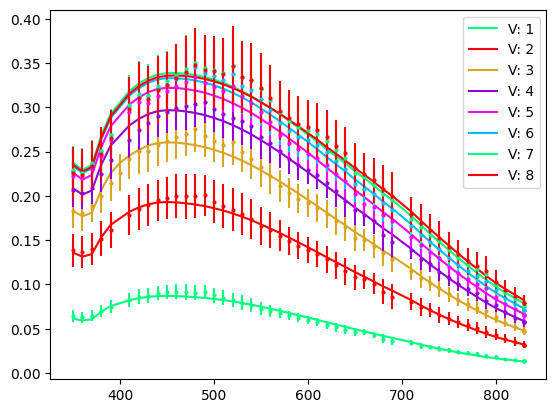

In [39]:
dict_final_global1 = {**resDict_global1, **fixedPars_global1}
print(dict_final_global1)

for dc in data_global1:
    oneD = dc.oneDData[0]
    xwlen = oneD["wlen"]
    y = oneD["yVals"]
    yErrs = oneD["yErrs"]
    
    voltage = dc.extraV
    localPe = peFull_dict_global1[voltage][0]
    localPh = phFull_dict_global1[voltage][0]
    pArgs = {"pe": localPe, "ph": localPh}
    
    col = ms.GetNextColor()
    
    yFit = PDE_allArgs(wlen=xwlen, theta1=oneD["theta1"], **dict_final_global1, **pArgs)
    plt.plot(xwlen, yFit, color = col, label=f"V: {dc.extraV}")
    
    plt.errorbar(xwlen, y, yerr=yErrs, color = col, linestyle = "", marker="o", markersize=2)
    
plt.legend()
plt.show()

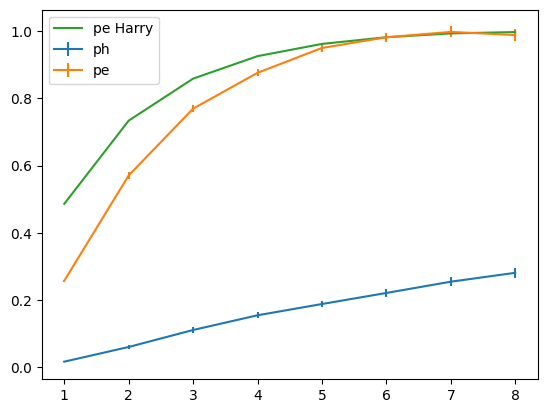

In [40]:
yph = [phFull_dict_global1[voltage][0] for voltage in voltageTracker]
yphErr = [phFull_dict_global1[voltage][1] for voltage in voltageTracker]

ype = [peFull_dict_global1[voltage][0] for voltage in voltageTracker]
ypeErr = [peFull_dict_global1[voltage][1] for voltage in voltageTracker]

yPeHarry = [harryPedict[V] for V in voltageTracker]

plt.errorbar(voltageTracker, yph, yphErr, label="ph")
plt.errorbar(voltageTracker, ype, ypeErr, label="pe")
plt.plot(voltageTracker, yPeHarry, label="pe Harry")
plt.legend()
plt.show()

---
### Another Full Fit. global2 - fix Harry's PE
* float global: $X_{pn}$, $dw^*$, $dp^*$
* nested float: $P_h$
* nested fixed: $P_e=$ Harry  
** __CRAZY RESULT BUT CAN MAKE IT WORK__

In [41]:
##-- Buiding Vis all dataset --##
print(data_voltages[1:])
data_global2 = []
for V in voltageTracker:
    dfA_t1 = df[(df['Overvoltage'] == V) & (df['Angle'] == angle_0A)]
    oneD_dict = {"wlen":dfA_t1['Wavelength'], "yVals": dfA_t1['PDE'], "yErrs": dfA_t1['PDE_error']*scaleErrors, "theta1": angle_0A}
    
    ## global dataset, float pe, ph
    fixedNuisDict = {"pe": harryPedict[V]}
    # print("V:", V, "pe:", harryPedict[V])
    
    fullFloat = {"ph": 0.15}
    fullBounds = {"ph": (0.0, 1.1)}
    odFull_global = SS.OneNuisanceDataSet(oneDData=oneD_dict, nuisanceFloat=fullFloat, nuisanceBounds=fullBounds,
                                    nuisanceFixed=fixedNuisDict)
    odFull_global.extraV = V
    data_global2.append(odFull_global)

[1 2 3 4 5 6 7 8]


In [42]:
# global fixed
print("List of args needed:", SS.GetNames(PDE_allArgs))

fixedPars_global2 = {"tOxide":ttGood, **fixedPars_Boring}
# "tOxide":(5, 50), "dp_star": (0.5, 5),
print("\nfixed inputs:", fixedPars_global2)

floatPars_global2 = {"dp_star":resDict_A_UVall["dp_star"], "Xpn": 10, "dw_star": 3e3}
floatParBounds_global2 = {"dp_star":(0.5, 2), "Xpn": (2, 100), "dw_star": (1.5e3, 15e3)}

x0_global2, x0_global2_Names = SS.BuildX0(floatDict=floatPars_global2, functionToFit=PDE_allArgs)
x0_global2_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_global2, functionToFit=PDE_allArgs)

print("------ Case global2 setup ------")

SS.GenericResiduals_Nuisance_1(globalFloat=x0_global2, globalFixed=fixedPars_global2, dataPackage=data_global2,
                               functionToFit=PDE_allArgs, verbose=False)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum']

fixed inputs: {'tOxide': 16.5, 'FF': 0.6, 'quantum': False, 'smoothSigma': None}
------ Case global2 setup ------


300.5166431941249

In [43]:
globalFit_global2 = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global2, bounds = x0_global2_bounds,
                                        args=(fixedPars_global2, data_global2, PDE_allArgs), method='migrad')
SS.GenericResiduals_Nuisance_1(globalFloat=globalFit_global2.x, globalFixed=fixedPars_global2, dataPackage=data_global2,
                                    functionToFit=PDE_allArgs, verbose=False)
print("Done fit!")

Done fit!


In [44]:
# print(globalFit_Visall_S)
print("score:", globalFit_global2.fun)
resDict_global2 = SS.GetResDict(globalFit_global2, x0_global2_Names)
resDictError_global2 = SS.GetResErrorDict(globalFit_global2, x0_global2_Names)

print(resDict_global2)
print(resDictError_global2)

phFull_dict_global2 = {dc.extraV: (dc.resultDict["ph"], dc.resultErrorsDict["ph"]) for dc in data_global2}

score: 263.9593537786941
{'dp_star': 1.3201, 'Xpn': 4.9636, 'dw_star': 2910.3351}
{'dp_star': 0.2277, 'Xpn': 0.9491, 'dw_star': 36.9568}


{'dp_star': 1.3201, 'Xpn': 4.9636, 'dw_star': 2910.3351, 'tOxide': 16.5, 'FF': 0.6, 'quantum': False, 'smoothSigma': None}


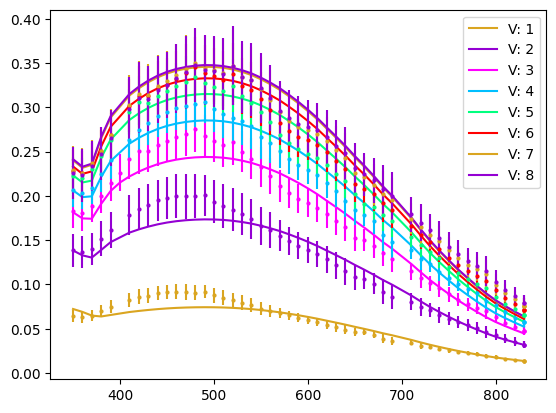

In [45]:
dict_final_global2 = {**resDict_global2, **fixedPars_global2}
print(dict_final_global2)

for dc in data_global2:
    oneD = dc.oneDData[0]
    xwlen = oneD["wlen"]
    y = oneD["yVals"]
    yErrs = oneD["yErrs"]
    
    voltage = dc.extraV
    localPh = phFull_dict_global2[voltage][0]
    pArgs = {"ph": localPh}
    
    col = ms.GetNextColor()
    
    yFit = PDE_allArgs(wlen=xwlen, theta1=oneD["theta1"], **dict_final_global2, **dc.mDict_nuisFixed, **pArgs)
    plt.plot(xwlen, yFit, color = col, label=f"V: {dc.extraV}")
    
    plt.errorbar(xwlen, y, yerr=yErrs, color = col, linestyle = "", marker="o", markersize=2)
    
plt.legend()
plt.show()

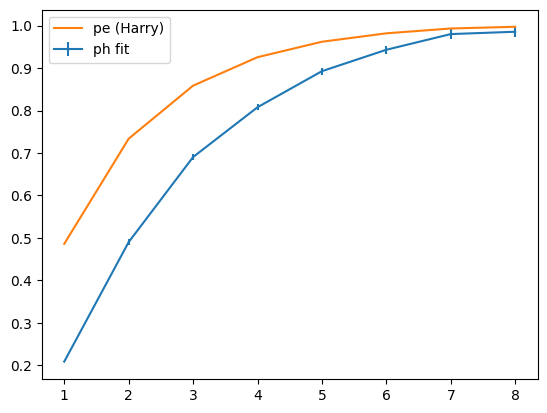

In [46]:
yph = [phFull_dict_global2[voltage][0] for voltage in voltageTracker]
yphErr = [phFull_dict_global2[voltage][1] for voltage in voltageTracker]
ype = [harryPedict[voltage] for voltage in voltageTracker]

plt.errorbar(voltageTracker, yph, yphErr, label="ph fit")
plt.plot(voltageTracker, ype, label="pe (Harry)")
plt.legend()
plt.show()

---
---
### Nesting Xpn v1: enforce Harry's Pe

* float global: $dw^*$, $dp^*$
* nested float: $X_{PN}$, $P_h$
* nested fixed: $P_e=$ Harry 

** FIT DOESN'T REALLY CONVERGE

In [47]:
# ##-- Buiding Vis all dataset --##
# print(data_voltages[1:])
# data_Xpn1 = []
# for V in voltageTracker:
#     dfA_t1 = df[(df['Overvoltage'] == V) & (df['Angle'] == angle_0A)]
#     oneD_dict = {"wlen":dfA_t1['Wavelength'], "yVals": dfA_t1['PDE'], "yErrs": dfA_t1['PDE_error']*scaleErrors, "theta1": angle_0A}
    
#     ## global dataset, float pe, ph
#     fixedNuisDict = {"pe": harryPedict[V]}
#     # print("V:", V, "pe:", harryPedict[V])
    
#     fullFloat = {"Xpn":6, "ph": peFull_dict_global1[voltage][0]}
#     fullBounds = {"Xpn":(3, 3e3), "ph": (0.0, 1.1)}
#     odFull_global = SS.OneNuisanceDataSet(oneDData=oneD_dict, nuisanceFloat=fullFloat, nuisanceBounds=fullBounds,
#                                     nuisanceFixed=fixedNuisDict)
#     odFull_global.extraV = V
#     data_Xpn1.append(odFull_global)

In [48]:
# # global fixed
# print("List of args needed:", SS.GetNames(PDE_allArgs))

# fixedPars_Xpn1 = {"tOxide":ttGood, **fixedPars_Boring}
# # "tOxide":(5, 50), "dp_star": (0.5, 5),
# print("\nfixed inputs:", fixedPars_Xpn1)

# floatPars_Xpn1 = {"dp_star":resDict_A_UVall["dp_star"], "dw_star": 3e3}
# floatParBounds_Xpn1 = {"dp_star":(0.2, 3), "dw_star": (2.5e3, 10e3)}

# x0_Xpn1, x0_Xpn1_Names = SS.BuildX0(floatDict=floatPars_Xpn1, functionToFit=PDE_allArgs)
# x0_Xpn1_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_Xpn1, functionToFit=PDE_allArgs)

# print("------ Case Xpn1 setup ------")

# SS.GenericResiduals_Nuisance_1(globalFloat=x0_Xpn1, globalFixed=fixedPars_Xpn1, dataPackage=data_Xpn1,
#                                functionToFit=PDE_allArgs, verbose=False)

In [49]:
# globalFit_Xpn1 = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_Xpn1, bounds = x0_Xpn1_bounds,
#                                         args=(fixedPars_Xpn1, data_Xpn1, PDE_allArgs), method='migrad')
# SS.GenericResiduals_Nuisance_1(globalFloat=globalFit_Xpn1.x, globalFixed=fixedPars_Xpn1, dataPackage=data_Xpn1,
#                                     functionToFit=PDE_allArgs, verbose=False)
# print("Done fit!")

In [50]:
# print(globalFit_Visall_S)
print("score:", globalFit_Xpn1.fun)
resDict_Xpn1 = SS.GetResDict(globalFit_Xpn1, x0_Xpn1_Names)
resDictError_Xpn1 = SS.GetResErrorDict(globalFit_Xpn1, x0_Xpn1_Names)

print(resDict_Xpn1)
print(resDictError_Xpn1)

phFull_dict_Xpn1 = {dc.extraV: (dc.resultDict["ph"], dc.resultErrorsDict["ph"]) for dc in data_Xpn1}
xpnFull_dict_Xpn1 = {dc.extraV: (dc.resultDict["Xpn"], dc.resultErrorsDict["Xpn"]) for dc in data_Xpn1}
print("ph:", phFull_dict_Xpn1)
print("Xpn:", xpnFull_dict_Xpn1)

NameError: name 'globalFit_Xpn1' is not defined

{'dp_star': 2.0521, 'dw_star': 2844.8263, 'tOxide': 16.5, 'FF': 0.6, 'quantum': False, 'smoothSigma': None}


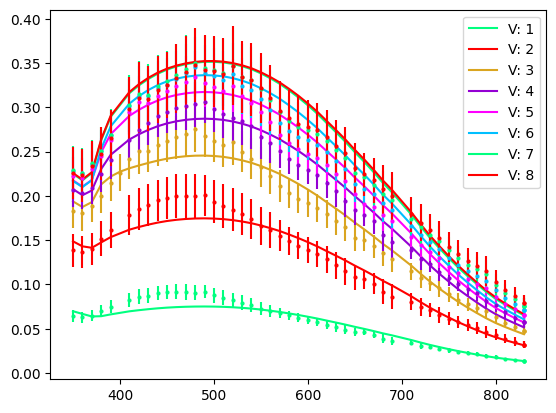

In [ ]:
dict_final_Xpn1 = {**resDict_Xpn1, **fixedPars_Xpn1}
print(dict_final_Xpn1)

for dc in data_Xpn1:
    oneD = dc.oneDData[0]
    xwlen = oneD["wlen"]
    y = oneD["yVals"]
    yErrs = oneD["yErrs"]
    
    voltage = dc.extraV
    localPh = phFull_dict_Xpn1[voltage][0]
    # pArgs = {"ph": localPh}
    
    col = ms.GetNextColor()
    
    yFit = PDE_allArgs(wlen=xwlen, theta1=oneD["theta1"], **dict_final_Xpn1, **dc.mDict_nuisFixed, **dc.resultDict)
    plt.plot(xwlen, yFit, color = col, label=f"V: {dc.extraV}")
    
    plt.errorbar(xwlen, y, yerr=yErrs, color = col, linestyle = "", marker="o", markersize=2)
    
plt.legend()
plt.show()

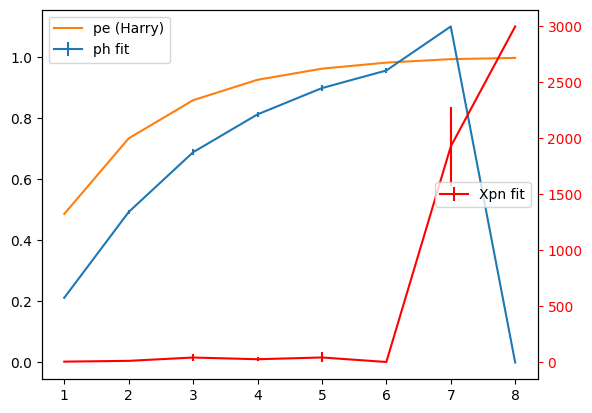

In [ ]:
yph = [phFull_dict_Xpn1[voltage][0] for voltage in voltageTracker]
yphErr = [phFull_dict_Xpn1[voltage][1] for voltage in voltageTracker]
ype = [harryPedict[voltage] for voltage in voltageTracker]

yxpn = [xpnFull_dict_Xpn1[voltage][0] for voltage in voltageTracker]
yxpnErr = [xpnFull_dict_Xpn1[voltage][1] for voltage in voltageTracker]

plt.errorbar(voltageTracker, yph, yphErr, label="ph fit")
plt.plot(voltageTracker, ype, label="pe (Harry)")
plt.legend()

ax = plt.gca()
ax2 = ax.twinx()
ax2.tick_params(axis='y', colors='red')
ax2.errorbar(voltageTracker, yxpn, yxpnErr, label="Xpn fit", color="red")

ax2.legend(loc="center right")
plt.show()

---
---
### Nesting Xpn v2: float $P_e$

AND the blip at 4V might even relate to field and signal to noise ratio stuff?

* float global: $dw^*$, $dp^*$
* nested float: $X_{PN}$, $P_h$, $P_e$

In [ ]:
##-- Buiding Vis all dataset --##
print(data_voltages[1:])
data_Xpn2 = []
for V in voltageTracker:
    dfA_t1 = df[(df['Overvoltage'] == V) & (df['Angle'] == angle_0A)]
    oneD_dict = {"wlen":dfA_t1['Wavelength'], "yVals": dfA_t1['PDE'], "yErrs": dfA_t1['PDE_error']*scaleErrors, "theta1": angle_0A}
    
    ## global dataset, float pe, ph
    fixedNuisDict = {}
    fullFloat = {"pe": peVals_A_dict[V], "Xpn":2e3, "ph": 0.15}
    fullBounds = {"pe":(0.0, 1.1), "Xpn":(5, 4e3), "ph": (0.0, 1.1)}
    odFull_global = SS.OneNuisanceDataSet(oneDData=oneD_dict, nuisanceFloat=fullFloat, nuisanceBounds=fullBounds,
                                    nuisanceFixed=fixedNuisDict)
    odFull_global.extraV = V
    data_Xpn2.append(odFull_global)
    
# global fixed
print("List of args needed:", SS.GetNames(PDE_allArgs))

fixedPars_Xpn2 = {"tOxide":ttGood, **fixedPars_Boring}
# "tOxide":(5, 50), "dp_star": (0.5, 5),
print("\nfixed inputs:", fixedPars_Xpn2)

floatPars_Xpn2 = {"dp_star":resDict_A_UVall["dp_star"], "dw_star": 10e3}
floatParBounds_Xpn2 = {"dp_star":(0.5, 5), "dw_star": (1.5e3, 15e3)}

x0_Xpn2, x0_Xpn2_Names = SS.BuildX0(floatDict=floatPars_Xpn2, functionToFit=PDE_allArgs)
x0_Xpn2_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_Xpn2, functionToFit=PDE_allArgs)

print("------ Case Xpn2 setup ------")
SS.GenericResiduals_Nuisance_1(globalFloat=x0_Xpn2, globalFixed=fixedPars_Xpn2, dataPackage=data_Xpn2,
                               functionToFit=PDE_allArgs, verbose=False)



[1 2 3 4 5 6 7 8]
List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum']

fixed inputs: {'tOxide': 16.5, 'FF': 0.6, 'quantum': False, 'smoothSigma': None}
------ Case Xpn2 setup ------


36.09967144245117

In [ ]:
globalFit_Xpn2 = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_Xpn2, bounds = x0_Xpn2_bounds,
                                        args=(fixedPars_Xpn2, data_Xpn2, PDE_allArgs), method='migrad')
SS.GenericResiduals_Nuisance_1(globalFloat=globalFit_Xpn2.x, globalFixed=fixedPars_Xpn2, dataPackage=data_Xpn2,
                                    functionToFit=PDE_allArgs, verbose=False)
print("Done fit!")

Done fit!


In [ ]:
# print(globalFit_Xpn2)
print("score:", globalFit_Xpn2.fun)
resDict_Xpn2 = SS.GetResDict(globalFit_Xpn2, x0_Xpn2_Names)
resDictError_Xpn2 = SS.GetResErrorDict(globalFit_Xpn2, x0_Xpn2_Names)

print(resDict_Xpn2)
print(resDictError_Xpn2)

phFull_dict_Xpn2 = {dc.extraV: (dc.resultDict["ph"], dc.resultErrorsDict["ph"]) for dc in data_Xpn2}
peFull_dict_Xpn2 = {dc.extraV: (dc.resultDict["pe"], dc.resultErrorsDict["pe"]) for dc in data_Xpn2}
xpnFull_dict_Xpn2 = {dc.extraV: (dc.resultDict["Xpn"], dc.resultErrorsDict["Xpn"]) for dc in data_Xpn2}
print("pe:", peFull_dict_Xpn2)
print("ph:", phFull_dict_Xpn2)
print("Xpn:", xpnFull_dict_Xpn2)

score: 26.01462404685281
{'dp_star': 1.4704, 'dw_star': 14859.8398}
{'dp_star': 0.2011, 'dw_star': 2067.8055}
pe: {1: (0.2691, 0.0054), 2: (0.5803, 0.0148), 3: (0.7698, 0.0139), 4: (0.8601, 0.0144), 5: (0.9396, 0.016), 6: (0.9611, 0.0181), 7: (0.9666, 0.0201), 8: (0.9546, 0.0213)}
ph: {1: (0.0205, 0.0028), 2: (0.0542, 0.0095), 3: (0.0857, 0.0105), 4: (0.1017, 0.0129), 5: (0.1334, 0.0138), 6: (0.1446, 0.0176), 7: (0.1515, 0.023), 8: (0.1616, 0.028)}
Xpn: {1: (1502.5976, 82.5591), 2: (1666.6264, 129.2708), 3: (1804.6462, 108.2945), 4: (2006.0739, 118.7867), 5: (1947.2809, 119.5699), 6: (2093.5083, 150.9347), 7: (2285.3978, 196.6428), 8: (2403.0244, 237.2759)}


{'dp_star': 1.4704, 'dw_star': 14859.8398, 'tOxide': 16.5, 'FF': 0.6, 'quantum': False, 'smoothSigma': None}


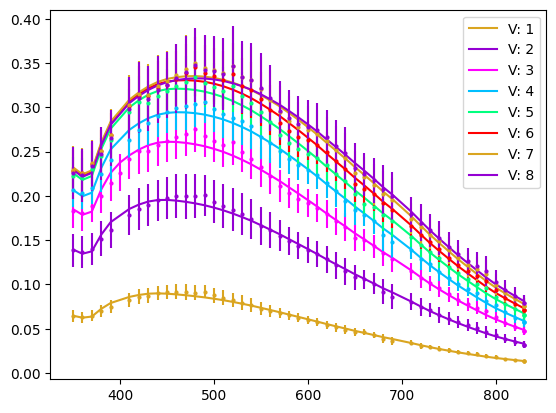

In [ ]:
dict_final_Xpn2 = {**resDict_Xpn2, **fixedPars_Xpn2}
print(dict_final_Xpn2)

for dc in data_Xpn2:
    oneD = dc.oneDData[0]
    xwlen = oneD["wlen"]
    y = oneD["yVals"]
    yErrs = oneD["yErrs"]
    
    voltage = dc.extraV
    localPh = phFull_dict_Xpn2[voltage][0]
    # pArgs = {"ph": localPh}
    
    col = ms.GetNextColor()
    
    yFit = PDE_allArgs(wlen=xwlen, theta1=oneD["theta1"], **dict_final_Xpn2, **dc.mDict_nuisFixed, **dc.resultDict)
    plt.plot(xwlen, yFit, color = col, label=f"V: {dc.extraV}")
    
    plt.errorbar(xwlen, y, yerr=yErrs, color = col, linestyle = "", marker="o", markersize=2)
    
plt.legend()
plt.show()


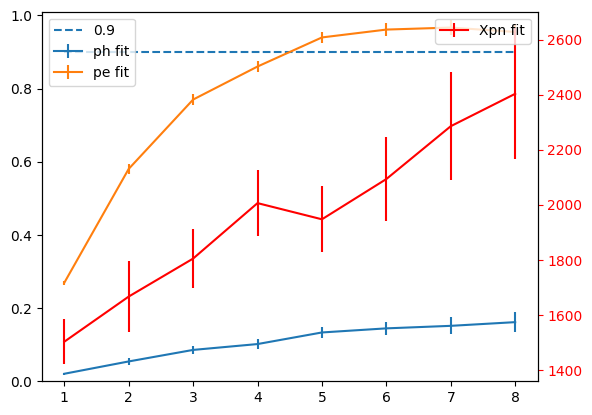

In [ ]:
yph = [phFull_dict_Xpn2[voltage][0] for voltage in voltageTracker]
yphErr = [phFull_dict_Xpn2[voltage][1] for voltage in voltageTracker]

ype = [peFull_dict_Xpn2[voltage][0] for voltage in voltageTracker]
ypeErr = [peFull_dict_Xpn2[voltage][1] for voltage in voltageTracker]

yxpn = [xpnFull_dict_Xpn2[voltage][0] for voltage in voltageTracker]
yxpnErr = [xpnFull_dict_Xpn2[voltage][1] for voltage in voltageTracker]

plt.errorbar(voltageTracker, yph, yphErr, label="ph fit")
plt.errorbar(voltageTracker, ype, ypeErr, label="pe fit")
plt.hlines(0.9, 1, 8, linestyle="--", label="0.9")
plt.legend()
ax = plt.gca()
ax.set_ylim(0, 1.01)

ax2 = ax.twinx()
ax2.tick_params(axis='y', colors='red')
ax2.errorbar(voltageTracker, yxpn, yxpnErr, label="Xpn fit", color="red")

plt.legend()
plt.show()

---
---
## Try to show P_h degeneracy - fit VStop

* fixed: $dp^*$ to previous fit
* float global: $X_{PN}$, $dw^*$
* nested float: $P_h$, $P_e$

This is the most informative example.
* __Vis degeneracy:__ Stop at 700nm, get small junction and high $P_h$. 
* __UV degeneracy:__ start at 400, force $dp^*$ large, get $P_e$ closer to Harry measured? __NOT REALLY__ 
But if you cut to 700nm, AND float $dp^*$ the result you get is 1.3nm instead of 1.5nm.

OKAY. Harry's Pe values. What if we nest dp^*, can we get Harry's P_e values. __NO__ (see below)

Go to 'Best Result, global1', which also floats $dp^*$. If you restrict it to sub 700nm dp_star goes from 1.5 to 1.3nm but have same result with $dw^*$ and $P_h$

In [ ]:
##-- Buiding Vis all dataset --##
print(data_voltages[1:])
data_VStop = []
wlenVStart = 200
wlenVEnd = 700
for V in voltageTracker:
    dfA_t1 = df[(df['Overvoltage'] == V) & (df['Angle'] == angle_0A) & (df['Wavelength'] >= wlenVStart) & (df['Wavelength'] <= wlenVEnd)]
    oneD_dict = {"wlen":dfA_t1['Wavelength'], "yVals": dfA_t1['PDE'], "yErrs": dfA_t1['PDE_error']*scaleErrors, "theta1": angle_0A}
    
    ## global dataset, float pe, ph
    fixedNuisDict = {}
    fullFloat = {"pe": peVals_A_dict[V], "ph": 0.4}
    fullBounds = {"pe":(0.0, 1.1), "ph": (0.0, 1.1)}
    odFull_global = SS.OneNuisanceDataSet(oneDData=oneD_dict, nuisanceFloat=fullFloat, nuisanceBounds=fullBounds,
                                    nuisanceFixed=fixedNuisDict)
    odFull_global.extraV = V
    data_VStop.append(odFull_global)

[1 2 3 4 5 6 7 8]


In [ ]:

# global fixed
print("List of args needed:", SS.GetNames(PDE_allArgs))

fixedPars_VStop = {"dp_star":1.5, "tOxide":ttGood, **fixedPars_Boring}
# "tOxide":(5, 50), "dp_star": (0.5, 5),
print("\nfixed inputs:", fixedPars_VStop)

floatPars_VStop = {"Xpn":2e3, "dw_star": 4e3}
floatParBounds_VStop = {"Xpn":(0.8e3, 3e3),  "dw_star": (2.5e3, 15e3)}

x0_VStop, x0_VStop_Names = SS.BuildX0(floatDict=floatPars_VStop, functionToFit=PDE_allArgs)
x0_VStop_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_VStop, functionToFit=PDE_allArgs)

print("------ Case VStop setup ------")
SS.GenericResiduals_Nuisance_1(globalFloat=x0_VStop, globalFixed=fixedPars_VStop, dataPackage=data_VStop,
                               functionToFit=PDE_allArgs, verbose=False)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum']

fixed inputs: {'dp_star': 1.5, 'tOxide': 16.5, 'FF': 0.6, 'quantum': False, 'smoothSigma': None}
------ Case VStop setup ------


27.16744812359589

In [ ]:
globalFit_VStop = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_VStop, bounds = x0_VStop_bounds,
                                        args=(fixedPars_VStop, data_VStop, PDE_allArgs), method='migrad')
SS.GenericResiduals_Nuisance_1(globalFloat=globalFit_VStop.x, globalFixed=fixedPars_VStop, dataPackage=data_VStop,
                                    functionToFit=PDE_allArgs, verbose=False)
print("Done fit!")


Done fit!


In [ ]:
# print(globalFit_VStop)
print("score:", globalFit_VStop.fun)
resDict_VStop = SS.GetResDict(globalFit_VStop, x0_VStop_Names)
resDictError_VStop = SS.GetResErrorDict(globalFit_VStop, x0_VStop_Names)

print(resDict_VStop)
print(resDictError_VStop)

phFull_dict_VStop = {dc.extraV: (dc.resultDict["ph"], dc.resultErrorsDict["ph"]) for dc in data_VStop}
peFull_dict_VStop = {dc.extraV: (dc.resultDict["pe"], dc.resultErrorsDict["pe"]) for dc in data_VStop}
print("pe:", peFull_dict_VStop)
print("ph:", phFull_dict_VStop)
dict_final_VStop = {**resDict_VStop, **fixedPars_VStop}
print(dict_final_VStop)

score: 18.551313921706285
{'dp_star': 1.3462, 'Xpn': 1699.9624, 'dw_star': 2694.103}
{'dp_star': 2.353, 'Xpn': 17.6144, 'dw_star': 17.8648}
pe: {1: (0.2656, 0.003), 2: (0.5758, 0.0135), 3: (0.7641, 0.0132), 4: (0.8546, 0.0141), 5: (0.9305, 0.0154), 6: (0.9514, 0.0178), 7: (0.9553, 0.0205), 8: (0.9418, 0.0158)}
ph: {1: (0.0, 0.0), 2: (0.1348, 0.0658), 3: (0.3429, 0.0667), 4: (0.566, 0.0718), 5: (0.638, 0.0791), 6: (0.8067, 0.0935), 7: (0.9938, 0.1106), 8: (1.1, 0.0007)}
{'dp_star': 1.3462, 'Xpn': 1699.9624, 'dw_star': 2694.103, 'tOxide': 16.5, 'FF': 0.6, 'quantum': False, 'smoothSigma': None}


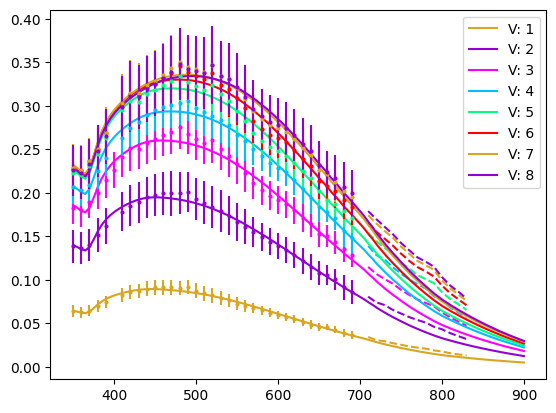

In [ ]:
for dc, dcToShowVis in zip(data_VStop, data_Xpn2):
    oneD = dc.oneDData[0]
    xwlen = oneD["wlen"]
    y = oneD["yVals"]
    yErrs = oneD["yErrs"]
    
    xFar_temp = dcToShowVis.oneDData[0]["wlen"]
    xFar = xFar_temp[xFar_temp > wlenVEnd]
    yFar_temp = dcToShowVis.oneDData[0]["yVals"]
    yFar = yFar_temp[xFar_temp > wlenVEnd]
    
    voltage = dc.extraV
    localPh = phFull_dict_VStop[voltage][0]
    # pArgs = {"ph": localPh}
    
    col = ms.GetNextColor()
    xFit = np.arange(min(xwlen), 900, 1)
    
    yFit = PDE_allArgs(wlen=xFit, theta1=oneD["theta1"], **dict_final_VStop, **dc.mDict_nuisFixed, **dc.resultDict)
    plt.plot(xFit, yFit, color = col, label=f"V: {dc.extraV}")
    
    plt.errorbar(xwlen, y, yerr=yErrs, color = col, linestyle = "", marker="o", markersize=2)
    plt.plot(xFar, yFar, color = col, linestyle = "--")
    
plt.legend()
plt.show()

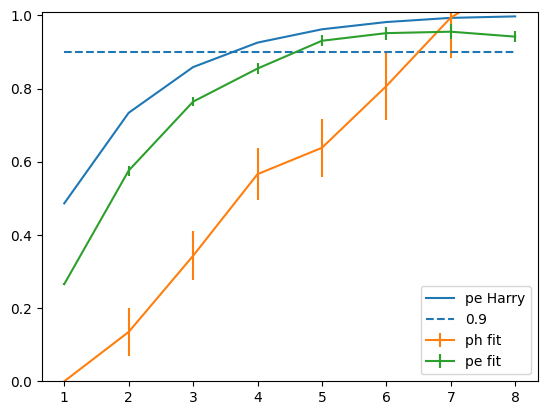

In [ ]:

yph = [phFull_dict_VStop[voltage][0] for voltage in voltageTracker]
yphErr = [phFull_dict_VStop[voltage][1] for voltage in voltageTracker]

ype = [peFull_dict_VStop[voltage][0] for voltage in voltageTracker]
ypeErr = [peFull_dict_VStop[voltage][1] for voltage in voltageTracker]

plt.plot(voltageTracker, yPeHarry, label="pe Harry")
plt.errorbar(voltageTracker, yph, yphErr, label="ph fit")
plt.errorbar(voltageTracker, ype, ypeErr, label="pe fit")
plt.hlines(0.9, 1, 8, linestyle="--", label="0.9")
plt.legend()
ax = plt.gca()
ax.set_ylim(0, 1.01)

plt.legend()
plt.show()

---
---
### UV all - hit Harry's Pe (nested dp*)

thank god this didn't work (otherwise diffusion in front, or growing region, would be real)

In [ ]:
print(data_voltages[1:])

data_UV_nested = []
wlenVStart = 200
wlenVEnd = 420
for V in voltageTracker:
    dfA_t1 = df[(df['Overvoltage'] == V) & (df['Angle'] == angle_0A) & (df['Wavelength'] >= wlenVStart) & (df['Wavelength'] <= wlenVEnd)]
    oneD_dict = {"wlen":dfA_t1['Wavelength'], "yVals": dfA_t1['PDE'], "yErrs": dfA_t1['PDE_error']*scaleErrors, "theta1": angle_0A}
    
    ## global dataset, float pe, ph
    fixedNuisDict = {}
    fullFloat = {"dp_star": 0.5, "pe": peFull_dict_global1[V][0]}
    fullBounds = {"dp_star": (0.1, 15), "pe":(0.0, 1.1)}
    odFull = SS.OneNuisanceDataSet(oneDData=oneD_dict, nuisanceFloat=fullFloat, nuisanceBounds=fullBounds,
                                    nuisanceFixed=fixedNuisDict)
    odFull.extraV = V
    data_UV_nested.append(odFull)
    
# global fixed
print("List of args needed:", SS.GetNames(PDE_allArgs))

fixedPars_UV_nested = {"tOxide":ttGood, "Xpn": 5e3, "dw_star":10e3, "ph":0.0, **fixedPars_Boring}

floatPars_UV_nested = {}
floatBounds_UV_nested_UV = {}

x0_UV_nested, x0_UV_nested_Names = SS.BuildX0(floatDict=floatPars_UV_nested, functionToFit=PDE_allArgs)
x0_UV_nested_bounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_UV_nested_UV, functionToFit=PDE_allArgs)

print("------ Case A-UVall setup ------")

scoreUV_nested = SS.GenericResiduals_Nuisance_1(globalFloat=x0_UV_nested, globalFixed=fixedPars_UV_nested, dataPackage=data_UV_nested,
                               functionToFit=PDE_allArgs, verbose=False)


print("chi2 score-ish:", scoreUV_nested)


[1 2 3 4 5 6 7 8]
List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum']
------ Case A-UVall setup ------
chi2 score-ish: 2.197278015349944


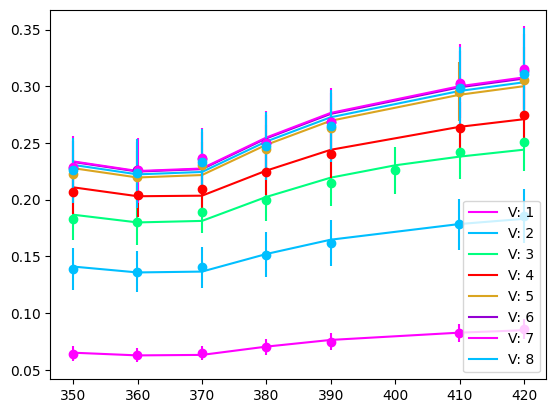

In [ ]:
for dc in data_UV_nested:
    oneD = dc.oneDData[0]
    xwlen = oneD["wlen"]
    y = oneD["yVals"]
    yErrs = oneD["yErrs"]
    
    col = ms.GetNextColor()
    
    yFit = PDE_allArgs(wlen=xwlen, theta1=oneD["theta1"], **dc.resultDict,  **fixedPars_UV_nested)
    plt.plot(xwlen, yFit, color = col, label=f"V: {dc.extraV}")
    
    plt.errorbar(xwlen, y, yerr=yErrs, color = col, linestyle = "", marker="o")
    
plt.legend()
plt.show()


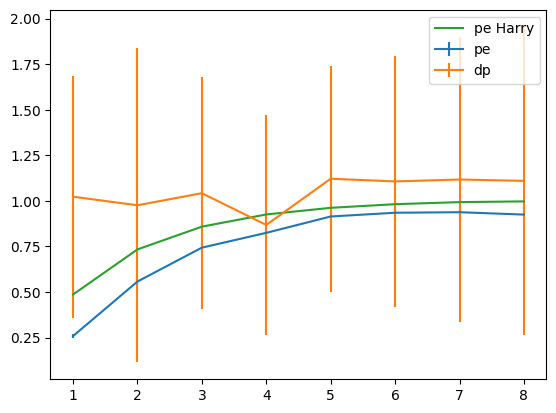

In [ ]:
peFull_dict_UVnested = {dc.extraV: (dc.resultDict["pe"], dc.resultErrorsDict["pe"]) for dc in data_UV_nested}
dpFull_dict_UVnested = {dc.extraV: (dc.resultDict["dp_star"], dc.resultErrorsDict["dp_star"]) for dc in data_UV_nested}

ype = [peFull_dict_UVnested[voltage][0] for voltage in voltageTracker]
ypeErr = [peFull_dict_UVnested[voltage][1] for voltage in voltageTracker]
ydp = [dpFull_dict_UVnested[voltage][0] for voltage in voltageTracker]
ydpErr = [dpFull_dict_UVnested[voltage][1] for voltage in voltageTracker]

plt.errorbar(voltageTracker, ype, ypeErr, label="pe")
plt.errorbar(voltageTracker, ydp, ydpErr, label="dp")

plt.plot(voltageTracker, yPeHarry, label="pe Harry")

plt.legend()
plt.show()

...diffusion | p+ | middle | n- | diffusion...


| p* | n* |         long fit

|diffusion | p+ |   short fit
| p++ | p |         short fit?

| p* | middle | n diffusion